In [1]:
import albumentations as A
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import os
import segmentation_models as sm
import tensorflow as tf
import tensorflow.keras.backend as K
import wandb
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.optimizers import Adam
from wandb.keras import WandbCallback

from networks import *

print(f'TensorFlow version: {tf.__version__}')
print(f'GPUs available: {tf.config.list_physical_devices("GPU")}')

Segmentation Models: using `keras` framework.
TensorFlow version: 2.12.0
GPUs available: []


In [2]:
HEIGHT = 240
WIDTH = 320
CHANNELS = 3
IMAGE_SHAPE = (HEIGHT, WIDTH, CHANNELS)
BATCH_SIZE = 4
EPOCHS = 50
STEPS_PER_EPOCH = 1000
LEARNING_RATE = 3e-4
MOMENTUM = 0.5
NUM_FILTERS = 32
DROPOUT = 0.0
DEEP_SUPERVISION = False
LOGGING = False

config = {
    'model': 'UNet',
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'steps_per_epoch': STEPS_PER_EPOCH,
    'loss': 'categorical_crossentropy',
    'optimizer': 'Adam',
    'learning_rate': LEARNING_RATE,
    'momentum': MOMENTUM,
    'num_filters': NUM_FILTERS,
    'dropout': DROPOUT,
    'image_shape': IMAGE_SHAPE,
    'deep_supervision': DEEP_SUPERVISION,
}

In [3]:
if LOGGING:
    wandb.login()
    wandb.init(project='PVID-assignment-4', config=config)

## Load dataset

In [4]:
# Load dataset
dataset_path = 'input/'
train_ds, val_ds, test_ds = load_dataset(
    dataset_path, val_split=0.1, batch_size=BATCH_SIZE,
    height=HEIGHT, width=WIDTH, channels=CHANNELS,
    preprocess=None, augment=True, repeat=True,
)

Class 0: Background (waterbody) [weight = 1.06]
Class 1: Human divers [weight = 14.62]
Class 2: Aquatic plants and sea-grass [weight = 15.72]
Class 3: Wrecks and ruins [weight = 5.1]
Class 4: Robots (AUVs/ROVs/instruments) [weight = 44.18]
Class 5: Reefs and invertebrates [weight = 1.0]
Class 6: Fish and vertebrates [weight = 4.78]
Class 7: Sea-floor and rocks [weight = 2.42]

Training set is repeated indefinitely.
Number of batches in validation set: 39
Number of batches in test set: 28

Image batch shape: (4, 240, 320, 3)
Mask batch shape: (4, 240, 320, 8)
Unique mask pixels:
 [[0. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 1.]
 [1. 0. 0.]
 [1. 0. 1.]
 [1. 1. 0.]]


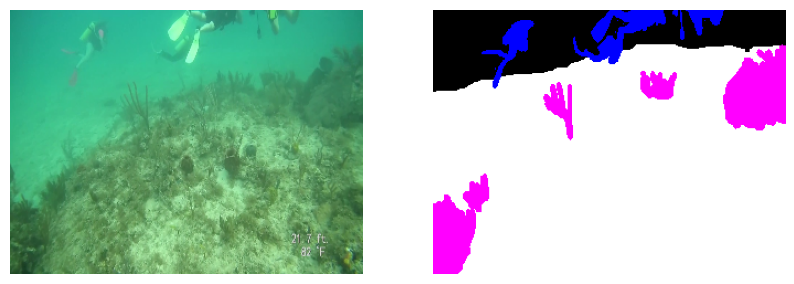

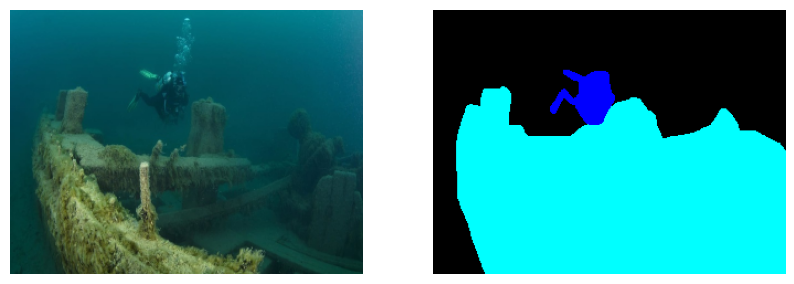

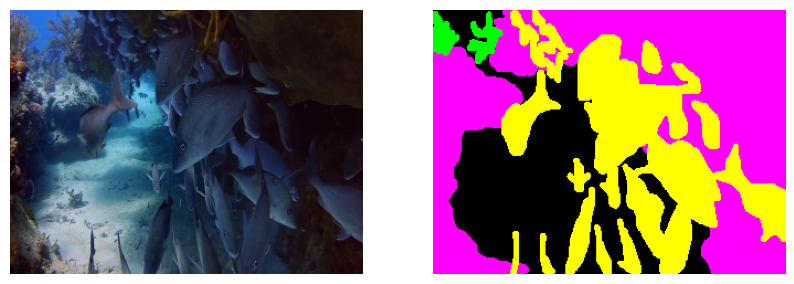

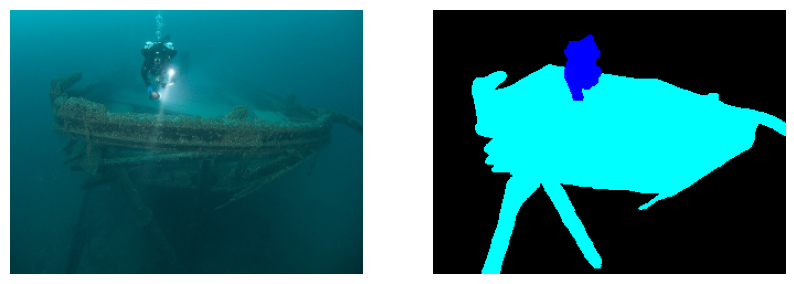

In [5]:
for code, name, weight in zip(CLASS_TO_COLOR.keys(), CLASS_NAMES, CLASS_WEIGHTS):
    print(f'Class {code}: {name} [weight = {weight}]')
print()

try:
    print('Number of batches in training set:', len(train_ds))
except TypeError:
    print('Training set is repeated indefinitely.')
print('Number of batches in validation set:', len(val_ds))
print('Number of batches in test set:', len(test_ds))
print()

data_batch = next(iter(val_ds))
images, masks = data_batch
print('Image batch shape:', images.shape)
print('Mask batch shape:', masks.shape)

reshaped = np.reshape(masks, (-1, 3))
mask_pixels = np.unique(reshaped, axis=0)
print('Unique mask pixels:\n', mask_pixels)

# Show some iamge-mask pairs for sanity check
for i, (img, mask) in enumerate(zip(images, masks)):
    if i > 4: break
    visualize_pair(img, mask, mask_type='one-hot')

## Training

In [6]:
# SM losses
sm_dice = sm.losses.DiceLoss(class_weights=CLASS_WEIGHTS)
sm_focal = sm.losses.CategoricalFocalLoss()
sm_cce = sm.losses.CategoricalCELoss(class_weights=CLASS_WEIGHTS)
sm_jac = sm.losses.JaccardLoss(class_weights=CLASS_WEIGHTS)
# sm_total_loss = (1. * sm_dice) + (1. * sm_focal) + (1. * sm_cce) + (1. * sm_jac)
sm_total_loss = sm.losses.categorical_focal_dice_loss

# SM metrics
sm_iou = sm.metrics.IOUScore(threshold=0.5)
sm_f1 = sm.metrics.FScore(threshold=0.5)

In [7]:
model = UNet(
    input_shape=IMAGE_SHAPE,
    num_classes=NUM_CLASSES,
    num_filters=NUM_FILTERS,
    dropout=DROPOUT,
    batchnorm=True,
    final_activation='softmax',
)

# model = UNetPlusPlus(
#     input_shape=IMAGE_SHAPE,
#     num_classes=NUM_CLASSES,
#     num_filters=NUM_FILTERS,
#     dropout=DROPOUT,
#     batchnorm=True,
#     final_activation='softmax',
#     deep_supervision=DEEP_SUPERVISION,
# )

# model = UNet3Plus(
#     input_shape=IMAGE_SHAPE,
#     num_classes=NUM_CLASSES,
#     num_filters=NUM_FILTERS,
#     dropout=DROPOUT,
#     batchnorm=True,
#     final_activation='softmax',
#     deep_supervision=DEEP_SUPERVISION,
# )

# model = Attention_UNet(
#     input_shape=IMAGE_SHAPE,
#     num_classes=NUM_CLASSES,
#     num_filters=NUM_FILTERS,
#     dropout=DROPOUT,
#     batchnorm=True,
#     final_activation='softmax',
# )

# model = Attention_ResUNet(
#     input_shape=IMAGE_SHAPE,
#     num_classes=NUM_CLASSES,
#     num_filters=NUM_FILTERS,
#     dropout=DROPOUT,
#     batchnorm=True,
#     final_activation='softmax',
# )

# model = SuimNet(
#     input_shape=IMAGE_SHAPE,
#     num_classes=NUM_CLASSES,
# )

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE, beta_1=MOMENTUM),
    loss=sm_total_loss,
    metrics=['accuracy', jaccard_coef, dice_coef, sm_iou, sm_f1],
)

tf.keras.utils.plot_model(model, show_shapes=True)
model.summary()

Model: "U-Net"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 240, 320, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_1 (Conv2D)              (None, 240, 320, 32  896         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization_1 (BatchNo  (None, 240, 320, 32  128        ['conv2d_1[0][0]']               
 rmalization)                   )                                                             

In [ ]:
# Take smaller dataset for debugging
EPOCHS = 3
STEPS_PER_EPOCH = 2
train_ds = train_ds.take(STEPS_PER_EPOCH)
val_ds = val_ds.take(STEPS_PER_EPOCH)

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5, verbose=1),
    EarlyStopping(monitor='val_loss', patience=10, verbose=1),
    VisualizeProgress(
        test_data=next(iter(val_ds)), every_n_epochs=1, num_samples=5,
        convert_mask=one_hot_to_rgb, deep_supervision=DEEP_SUPERVISION, log=LOGGING,
    ),
]
if LOGGING:
    callbacks.append(WandbCallback())

history = model.fit(
    train_ds, validation_data=val_ds, validation_steps=len(val_ds),
    epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH,
    callbacks=callbacks, verbose=1,
)

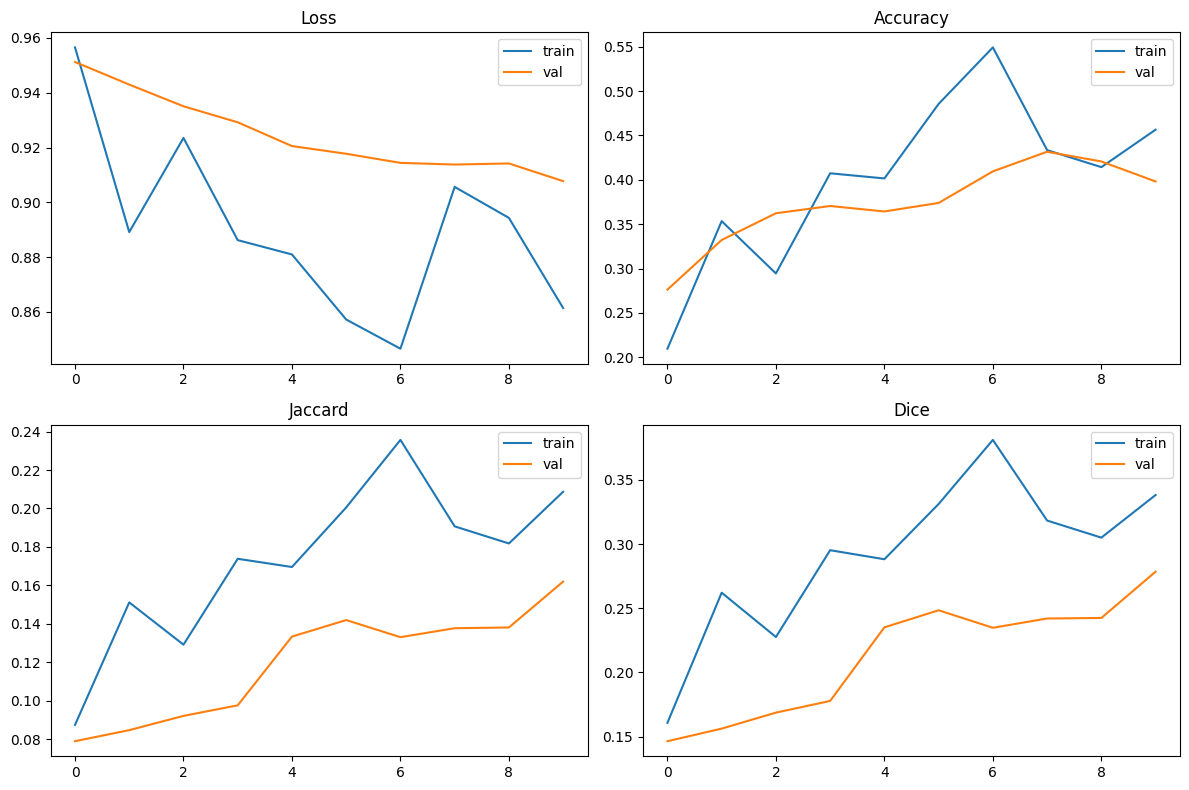

In [9]:
plot_history(history)

In [ ]:
# save model
model.save('models/unet.h5')

In [ ]:
if LOGGING:
    wandb.finish()